# Misión: tu gemelo de Star Wars

Vamos a buscar qué personaje de Star Wars se parece más a ti en altura y peso.

Antes de nada, comprueba que arriba a la derecha está elegido el kernel .venv. Si no, pulsa Select Kernel y elígelo.

Las celdas que ya traen código, ejecútalas con Shift + Enter. Las vacías, debajo de cada "Ahora tú", las escribes tú. En el texto siempre hay un ejemplo parecido para copiarlo y cambiarlo.

Si te sale un error, mira la última línea y comprueba que has ejecutado en orden las celdas de arriba. Si sigues atascado, pregunta en el chat: seguro que a alguien le ha pasado lo mismo.

Cuando encuentres a tu gemelo, pega su foto y su nombre en el chat.

## 1. Preparar

In [111]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 22.6 MB/s  0:00:00
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
Using cached pillow-12.3.0-cp314-cp314-macosx_11_0_arm64.whl (4.8 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [matplotlib]7 [matpl

In [112]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Image, display

print("Todo listo")

Todo listo


## 2. Pedir los personajes a la API

Con una sola URL nos llegan todos los personajes, en una lista con un diccionario para cada uno. Debería salir 87.

In [113]:
url = "https://akabab.github.io/starwars-api/api/all.json"
personajes = requests.get(url).json()
print("Personajes:", len(personajes))

Personajes: 87


Si la celda anterior ha funcionado, sáltate la siguiente y pasa al paso 3. Si ha dado error porque no hay internet o la API no contesta, ejecuta la siguiente: lee los mismos datos del fichero que hay en la carpeta datos.

In [114]:
import json
personajes = json.load(open("datos/personajes.json", encoding="utf-8"))
print("Personajes:", len(personajes))

Personajes: 87


## 3. Un personaje es un diccionario

Cada personaje de la lista es un diccionario. Para ver uno se pone su posición entre corchetes: personajes[0] es el primero.

Ahora tú. Enseña el primer personaje de la lista.

In [115]:
personajes[0]

{'id': 1,
 'name': 'Luke Skywalker',
 'height': 1.72,
 'mass': 73,
 'gender': 'male',
 'homeworld': 'tatooine',
 'wiki': 'http://starwars.wikia.com/wiki/Luke_Skywalker',
 'image': 'https://vignette.wikia.nocookie.net/starwars/images/2/20/LukeTLJ.jpg',
 'born': -19,
 'bornLocation': 'polis massa',
 'died': 34,
 'diedLocation': 'ahch-to',
 'species': 'human',
 'hairColor': 'blond',
 'eyeColor': 'blue',
 'skinColor': 'light',
 'cybernetics': 'Prosthetic right hand',
 'affiliations': ['Alliance to Restore the Republic',
  'Red Squadron',
  'Rogue Squadron',
  'Massassi Group',
  "Leia Organa's team",
  'Endor strike team',
  'Jedi Order',
  'Bright Tree tribe',
  'New Republic',
  'Resistance'],
 'masters': ['Obi-Wan Kenobi', 'Yoda'],
 'apprentices': ['Leia Organa',
  'Ben Solo (along with a dozen apprentices)',
  'Rey'],
 'formerAffiliations': []}

Para sacar un dato, detrás de la posición va la clave entre corchetes. Por ejemplo, personajes[0]["name"] es el nombre del primero.

Ahora tú. Enseña con dos print el nombre y la altura (height) del primero. Debería salir Luke Skywalker, 1.72.

In [116]:
print("Nombre", personajes[0]["name"])
print("Altura", personajes[0]["height"])

Nombre Luke Skywalker
Altura 1.72


Ahora tú. Lo mismo con el personaje de la posición 3. Debería salir Darth Vader, 2.03.

In [117]:
print("Nombre", personajes[3]["name"])
print("Altura", personajes[3]["height"])

Nombre Darth Vader
Altura 2.03


## 4. Su foto

Las fotos están en la carpeta datos/fotos y cada una se llama con el id del personaje. La de Luke es 1.jpg. Se enseñan así:

Image("datos/fotos/" + str(personajes[0]["id"]) + ".jpg", width=200)

El str hace falta para pegar el número al resto del texto.

Ahora tú. Enseña la foto de Luke.

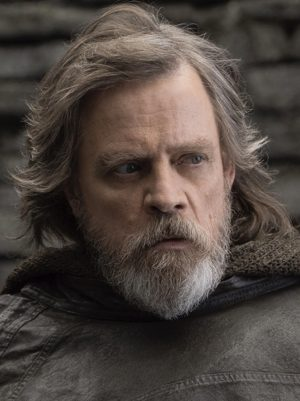

In [118]:
Image("datos/fotos/" + str(personajes[0]["id"]) + ".jpg", width=200)

Ahora tú. Y la de Darth Vader, el de la posición 3.

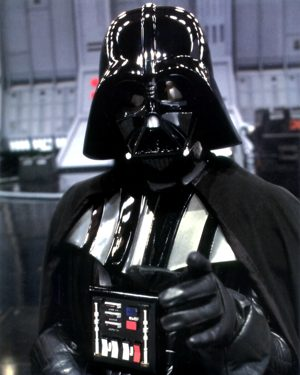

In [119]:
Image("datos/fotos/" + str(personajes[3]["id"]) + ".jpg", width=200)

## 5. De la lista a una tabla

pandas convierte la lista en una tabla, y cada diccionario pasa a ser una fila. Nos quedamos con seis columnas y las ponemos en español. Donde falta un dato sale NaN, porque de algunos personajes no se sabe el peso. Esta celda ya está hecha: ejecútala.

In [120]:
tabla = pd.DataFrame(personajes)
tabla = tabla[["id", "name", "height", "mass", "species", "homeworld"]]
tabla.columns = ["id", "nombre", "altura", "peso", "especie", "planeta"]
tabla

,id,nombre,altura,peso,especie,planeta
0,1,Luke Skywalker,1.72,73.0,human,tatooine
1,2,C-3PO,1.71,75.0,droid,tatooine
2,3,R2-D2,1.09,32.0,droid,naboo
3,4,Darth Vader,2.03,120.0,human,tatooine
4,5,Leia Organa,1.50,51.0,human,alderaan
...,...,...,...,...,...,...
82,84,Finn,1.78,73.0,human,NaN
83,85,Rey,1.70,54.0,human,jakku
84,86,Poe Dameron,1.72,80.0,human,yavin 4
85,87,BB8,0.67,18.0,droid,NaN


Ahora tú. ¿Cuál es la altura más alta? Escribe tabla["altura"] y detrás .max(). Debería salir 3.9.

In [121]:
tabla["altura"].max()

np.float64(3.9)

Ahora tú. ¿De quién es? Enseña su fila, igual que buscamos ayer el día más caluroso. Se hace con tabla[tabla["altura"] == ...], poniendo en los puntos el número que te ha salido. Debería salir Jabba Desilijic Tiure.

In [122]:
maxima = tabla["altura"].max()
tabla[tabla["altura"] == maxima]

,id,nombre,altura,peso,especie,planeta
15,16,Jabba Desilijic Tiure,3.9,1358.0,hutt,tatooine


Ahora tú. ¿Y quién pesa menos? Lo mismo con la columna peso y .min(). Debería salir Yoda, con 13 kilos.

In [123]:
minimo = tabla["peso"].min()
tabla[tabla["peso"] == minimo]

,id,nombre,altura,peso,especie,planeta
18,20,Yoda,0.66,13.0,yoda's species,NaN


## 6. Tus datos

Ahora tú. Crea dos variables, mi_altura en metros y mi_peso en kilos. La altura va con punto y sin comillas, por ejemplo mi_altura = 1.75. Si no quieres poner los tuyos, invéntatelos o pon los de algún famoso, que no los ve nadie.

In [124]:
mi_altura = 1.75
mi_peso = 70

Ahora tú. ¿Cuántos personajes son más altos que tú? Fíltralos con tabla[tabla["altura"] > mi_altura] y cuenta las filas con len.

In [125]:
mas_altos = tabla[tabla["altura"] > mi_altura]
print("Personajes más altos que yo:", len(mas_altos))

Personajes más altos que yo: 50


## 7. ¿Cuánto se parece cada uno a ti?

Para cada personaje sumamos los centímetros que os lleváis de altura y los kilos que os lleváis de peso. Cuanto más bajo sea el número, más se parece. abs() quita el signo menos, así da igual quién sea más alto. Esta celda ya está hecha: ejecútala.

Si te sale NameError: name 'mi_altura' is not defined, es que falta ejecutar la celda del paso 6.

In [126]:
tabla["dif_altura"] = (tabla["altura"] - mi_altura).abs() * 100
tabla["dif_peso"] = (tabla["peso"] - mi_peso).abs()
tabla["diferencia"] = tabla["dif_altura"] + tabla["dif_peso"]
tabla

,id,nombre,altura,peso,especie,planeta,dif_altura,dif_peso,diferencia
0,1,Luke Skywalker,1.72,73.0,human,tatooine,3.0,3.0,6.0
1,2,C-3PO,1.71,75.0,droid,tatooine,4.0,5.0,9.0
2,3,R2-D2,1.09,32.0,droid,naboo,66.0,38.0,104.0
3,4,Darth Vader,2.03,120.0,human,tatooine,28.0,50.0,78.0
4,5,Leia Organa,1.50,51.0,human,alderaan,25.0,19.0,44.0
...,...,...,...,...,...,...,...,...,...
82,84,Finn,1.78,73.0,human,NaN,3.0,3.0,6.0
83,85,Rey,1.70,54.0,human,jakku,5.0,16.0,21.0
84,86,Poe Dameron,1.72,80.0,human,yavin 4,3.0,10.0,13.0
85,87,BB8,0.67,18.0,droid,NaN,108.0,52.0,160.0


Ahora tú. Ordena la tabla de menor a mayor diferencia y guárdala en ordenada. Se hace con tabla.sort_values("diferencia"). Los que no tienen peso se van al final.

In [127]:
ordenada = tabla.sort_values(by="diferencia")
ordenada

,id,nombre,altura,peso,especie,planeta,dif_altura,dif_peso,diferencia
14,15,Greedo,1.74,74.0,rodian,"[Rodia, Tatooine]",1.0,4.0,5.0
0,1,Luke Skywalker,1.72,73.0,human,tatooine,3.0,3.0,6.0
82,84,Finn,1.78,73.0,human,NaN,3.0,3.0,6.0
19,21,Palpatine,1.78,75.0,human,naboo,3.0,5.0,8.0
24,26,Lobot,1.75,79.0,human,bespin,0.0,9.0,9.0
...,...,...,...,...,...,...,...,...,...
66,68,Bail Prestor Organa,1.91,NaN,human,alderaan,16.0,NaN,NaN
71,73,Taun We,2.13,NaN,kaminoan,kamino,38.0,NaN,NaN
72,74,Jocasta Nu,1.69,NaN,human,coruscant,6.0,NaN,NaN
73,75,R4-P17,1.09,NaN,droid,NaN,66.0,NaN,NaN


Ahora tú. Enseña solo los 3 que más se parecen a ti. Escribe ordenada y detrás .head(3).

In [128]:
ordenada.head(3)

,id,nombre,altura,peso,especie,planeta,dif_altura,dif_peso,diferencia
14,15,Greedo,1.74,74.0,rodian,"[Rodia, Tatooine]",1.0,4.0,5.0
0,1,Luke Skywalker,1.72,73.0,human,tatooine,3.0,3.0,6.0
82,84,Finn,1.78,73.0,human,NaN,3.0,3.0,6.0


## 8. Tu gemelo

El primero de la tabla ordenada es tu gemelo. ordenada.iloc[0] coge la primera fila, y una fila se usa igual que un diccionario: gemelo["nombre"] es su nombre.

Ahora tú. Guarda la primera fila en gemelo con gemelo = ordenada.iloc[0]. Después enseña su nombre con un print y su foto como en el paso 4, pero con gemelo["id"].

Mi gemelo es: Greedo


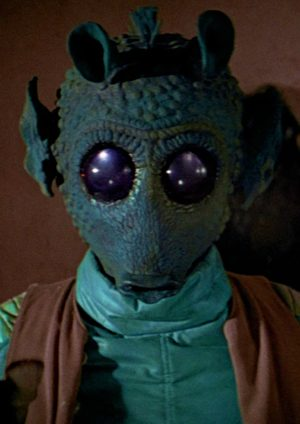

In [129]:
gemelo = ordenada.iloc[0]
print("Mi gemelo es:", gemelo["nombre"])
Image("datos/fotos/" + str(gemelo["id"]) + ".jpg", width=200)

Haz una captura de la foto y pégala en el chat con su nombre. En Mac, Cmd + Shift + 4 y seleccionas la foto; en Windows, Windows + Shift + S.

## Más retos

Ahora tú. ¿Quién es tu segundo gemelo? Igual que en el paso 8, con iloc[1].

Mi gemelo es: Luke Skywalker


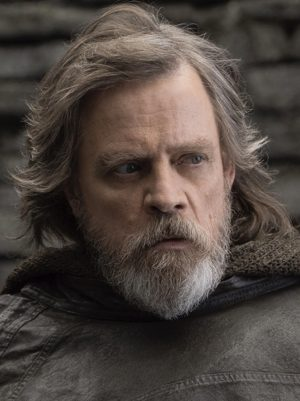

In [130]:
gemelo = ordenada.iloc[1]
print("Mi gemelo es:", gemelo["nombre"])
Image("datos/fotos/" + str(gemelo["id"]) + ".jpg", width=200)

Ahora tú. ¿Quiénes son de Tatooine, el planeta de Luke? Filtra la columna planeta con "tatooine", en minúsculas, y guárdalos en de_tatooine. Deberían salir 11.

In [131]:
de_tatooine = tabla[tabla["planeta"] == "tatooine"]
de_tatooine

,id,nombre,altura,peso,especie,planeta,dif_altura,dif_peso,diferencia
0,1,Luke Skywalker,1.72,73.0,human,tatooine,3.0,3.0,6.0
1,2,C-3PO,1.71,75.0,droid,tatooine,4.0,5.0,9.0
3,4,Darth Vader,2.03,120.0,human,tatooine,28.0,50.0,78.0
5,6,Owen Lars,1.70,120.0,human,tatooine,5.0,50.0,55.0
6,7,Beru Whitesun lars,1.65,75.0,human,tatooine,10.0,5.0,15.0
7,8,R5-D4,0.97,32.0,droid,tatooine,78.0,38.0,116.0
8,9,Biggs Darklighter,1.83,84.0,human,tatooine,8.0,14.0,22.0
10,11,Anakin Skywalker,2.03,120.0,human,tatooine,28.0,50.0,78.0
15,16,Jabba Desilijic Tiure,3.90,1358.0,hutt,tatooine,215.0,1288.0,1503.0
41,43,Shmi Skywalker,1.63,NaN,human,tatooine,12.0,NaN,NaN


Para enseñar varias fotos seguidas se usa un for, que enseña una en cada vuelta. Con display, cada foto sale debajo de la anterior:

for numero in de_tatooine["id"]:
    display(Image("datos/fotos/" + str(numero) + ".jpg", width=120))

Ahora tú. Haz la galería de los de Tatooine.

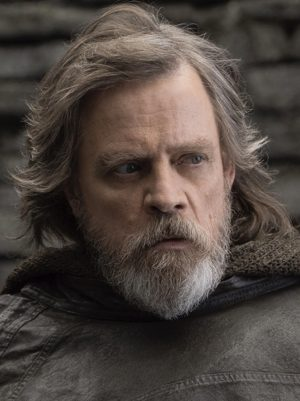

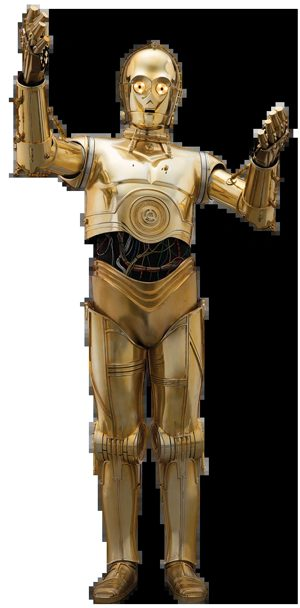

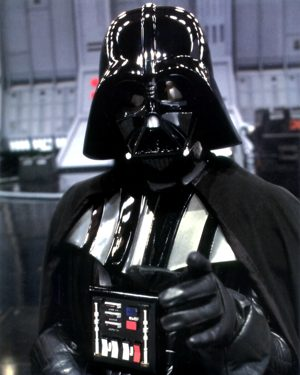

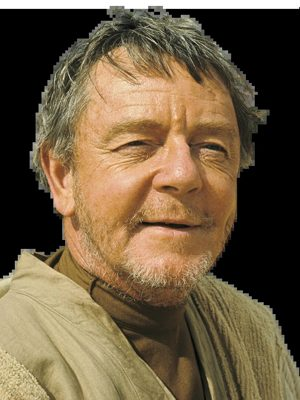

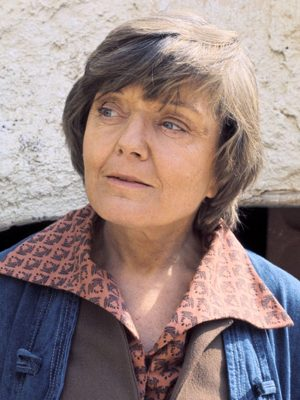

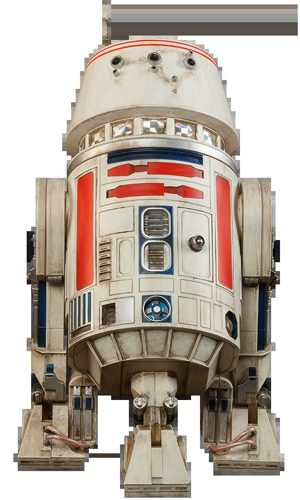

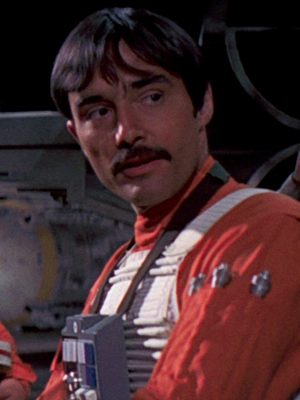

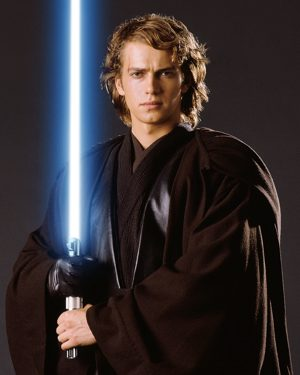

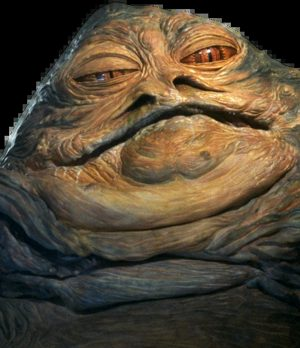

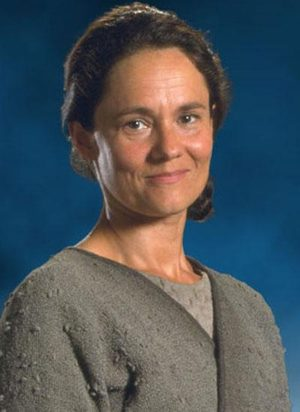

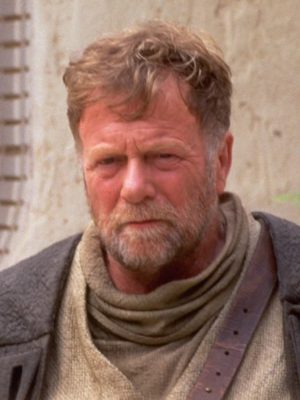

In [132]:
for numero in de_tatooine["id"]:
    display(Image("datos/fotos/" + str(numero) + ".jpg", width=200))

Ahora tú. Haz la galería de los droides. Primero fíltralos (su especie es "droid") y luego el mismo for. Deberían salir 6.

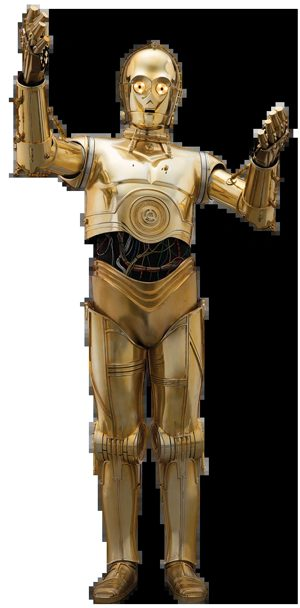

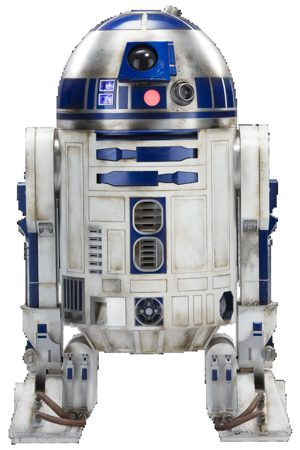

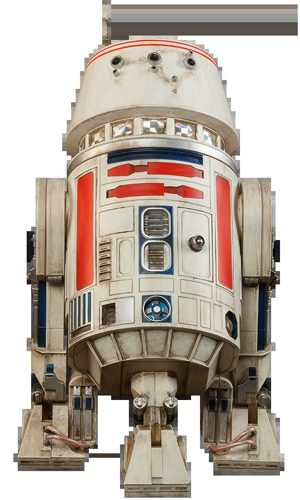

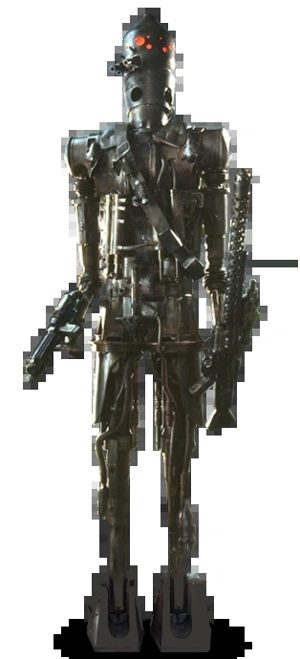

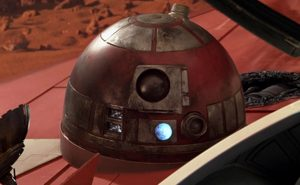

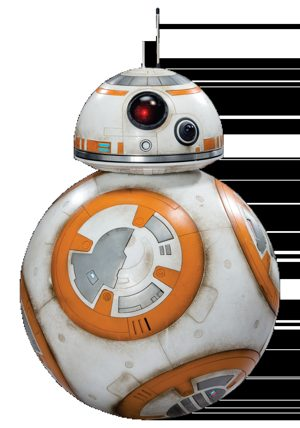

In [133]:
droides = tabla[tabla["especie"] == "droid"]

for numero in droides["id"]:
    display(Image("datos/fotos/" + str(numero) + ".jpg", width=200))

Cada personaje tiene una clave affiliations con la lista de grupos a los que pertenece. Así se mira si el primero, Luke, es Jedi (da True o False):

"Jedi Order" in personajes[0]["affiliations"]

Ahora tú. Con un for que recorra personajes y un if dentro, enseña el nombre de todos los Jedi. Deberían salir 18.

In [134]:
for p in personajes:
    if "Jedi Order" in p["affiliations"]:
        print(p["name"])        

Luke Skywalker
Obi-Wan Kenobi
Yoda
Qui-Gon Jinn
Ayla Secura
Mace Windu
Ki-Adi-Mundi
Kit Fisto
Eeth Koth
Adi Gallia
Saesee Tiin
Yarael Poof
Plo Koon
Luminara Unduli
Barriss Offee
Jocasta Nu
Shaak Ti
Rey


Ahora tú. ¿Y cuántos Sith hay? En su lista aparece "Sith". Cuéntalos con un contador, como hacíamos en el zombi: empieza en 0 y súmale 1 cada vez que encuentres uno. Deberían salir 5.

In [135]:
sith = 0
for p in personajes:
    if "Sith" in p["affiliations"]:
        sith += 1
        print(p["name"])        
print("Cantidad de Sith:", sith)        

Darth Vader
Anakin Skywalker
Palpatine
Darth Maul
Dooku
Cantidad de Sith: 5


Ahora tú. ¿Qué droide se parece más a ti? Filtra la tabla ordenada (ordenada) por la especie "droid" y enseña el primero con .head(1).

In [136]:
droides_parecidos = ordenada[ordenada["especie"] == "droid"]
droides_parecidos.head(1)

,id,nombre,altura,peso,especie,planeta,dif_altura,dif_peso,diferencia
1,2,C-3PO,1.71,75.0,droid,tatooine,4.0,5.0,9.0


Ahora tú. Haz el gráfico de altura y peso, un punto por personaje, con tabla.plot(kind="scatter", x="altura", y="peso"). ¿Quién es el que está solo arriba a la derecha?

<Axes: title={'center': 'Altura vs Peso'}, xlabel='altura', ylabel='peso'>

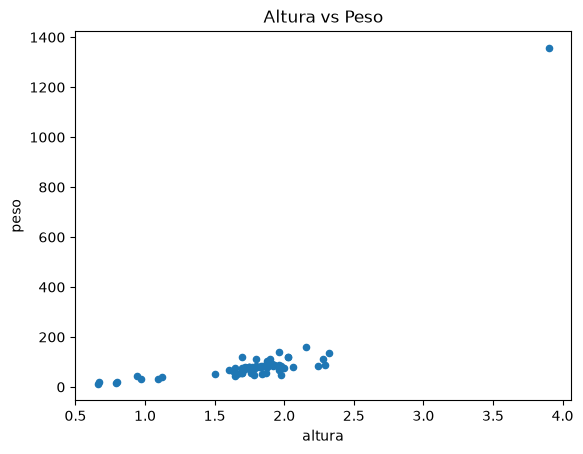

In [137]:
tabla.plot(kind="scatter", x="altura", y="peso", title="Altura vs Peso")

Ahora tú. Busca el gemelo de algún amigo, de alguien de tu familia o de un famoso. Cambia mi_altura y mi_peso en el paso 6 y vuelve a ejecutar desde ahí hasta el paso 8.